# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：**伍亭妤　**學號／組別：**C114118128　**完成日期：**2026/11/25

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [2]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


## 📝 學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：**固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：高科AI，提示詞：你好我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。請分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：隨機種子（seed）：不只是「設了種子就固定」，種子是隨機數流的起點，取多少和依什麼順序消耗都會改變結果，資料版本：資料變了，程式碼再怎麼固定都沒用，套件版本與環境：同一行程式碼在不同版本行為可能不同，路徑：Notebook 的「起點」不是你以為的地方，執行順序：Notebook 最大的重現性殺手
- 我的理解與具體例子：種子是隨機的，當中途變更後輸出結果也會隨之更改。資料版本原始檔案更改即使程式碼相同結果也會不一樣。當程式碼相同時如果套件版本相同輸出結果也不同。而當啟動位置不同，路徑可能就會指向不同檔案或者找不到。notebook的格子編號不等於執行順序。例子：當我隨機求四個種子(X1、X2和Y1、Y2)當我X1和Y1正常輸出，但Y1和Y2中間多取了一次隨機數則最終輸出的(X1,Y1)將不等於(X2,Y2)。
- 查證來源／方式及日期（無法查證請註明）：種子：https://numpy.org/doc/2.2/reference/random/legacy.html
  日期：2026/11/20
- 我檢查或修正 AI 回答的地方：無


## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [3]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.14.2
numpy： 2.4.6 pandas： 3.0.2
matplotlib： 3.10.8 scikit-learn： 1.8.0


## 📝 學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：**一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：你好我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。請分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：主張的關鍵要求：一句話、可證偽；寫出對象、比較基準、期間、方向與幅度。對應圖表的關鍵要求：標明圖或表編號；標題要寫清變數、期間與 n；一個主張對應一個表／圖。有效筆數關鍵要求：寫出「原始筆數 → 排除條件 → 分析筆數」；不同欄位的 n 可能不同，要分開標。限制的關鍵要求：至少寫樣本範圍、缺漏處理、能否推因果、重複觀察／多重比較 
- 我的理解與具體例子：主張要求一句話講完，且讓人能用同一份資料反駁，然後一個主張要對應一張圖表，而有效筆數要分成原始筆數、重複、條件排除、該欄實際算到的筆數這四層，限制則是要寫這些資料缺了東西怎麼處理，例子：當在notebook裡自建10 筆含缺失、重複與負值的資料，依序印出 len(df)、df.duplicated().sum()、df.count()，再去重複、篩掉負值後重算一次。會發現同一份資料在不同處理階段，筆數會一直變，所以主張裡不能只寫「共有 N 筆」。
- 查證來源／方式及日期（無法查證請註明）：https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html 日期：2026/11/20
- 我檢查或修正 AI 回答的地方：無


## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。-問題：探討學生的學習習慣（讀書時間、睡眠時間、螢幕使用時間、出席率）與系所別，對測驗成績（quiz_score）的分布與關聯性。模擬資料：透過Python（numpy 固定隨機種子42）依設定公式與常態分布生成的60筆模擬學生紀錄。主要欄位：類別欄位：student_id、department［資訊管理、企業管理、金融管理］數值欄位：sleep_hours、screen_time_hours、study_hours、attendance_rate、quiz_score
2. 缺失、異常、重複的實際結果與處理理由。-缺失值有2筆，處理方式與理由：在計算「睡眠與成績」相關分析時採用成對刪除，有效分析筆數為 58 筆。異常值有1筆，處理方式與理由：由於每天 24 小時中螢幕使用 15 小時在現實中雖屬極端但仍有可能發生，因此選擇保留該筆資料進行主分析，並在限制中註明其對平均數的潛在拉高影響。
3. 至少兩張圖、分組與變數關係。-(在下方)圖 1：各系所測驗成績分布箱型圖比較「資訊管理」、「企業管理」與「金融管理」三系學生的成績中位數與離散程度，觀察不同分組間的表現差異。圖 2：每日睡眠時間與測驗成績散佈圖觀察睡眠時數與成績之間的線性趨勢。
4. 處理方案比較及限制。-缺失值處理比較：方案A：保留未缺失欄位的資料，缺點是不同圖表的有效筆數不一致，需逐一標明。方案B：可維持所有分析皆為 60 筆，但會人為壓低變異數並扭曲與成績的真實相關性。故本報告採用方案 A。而限制有無法推論因果或真實情況、資料洩漏風險、人為品質干擾不可逆。
6. AI 提示詞、人工修改、錯誤及驗證。提示詞：參考08-Q1與08-Q2的提問架構，限定AI扮演助教角色、使用繁體中文與台灣慣用語，並要求「不要虛構結果、不要假設程式輸出」。
7. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：**本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 上方第三點講的兩張圖

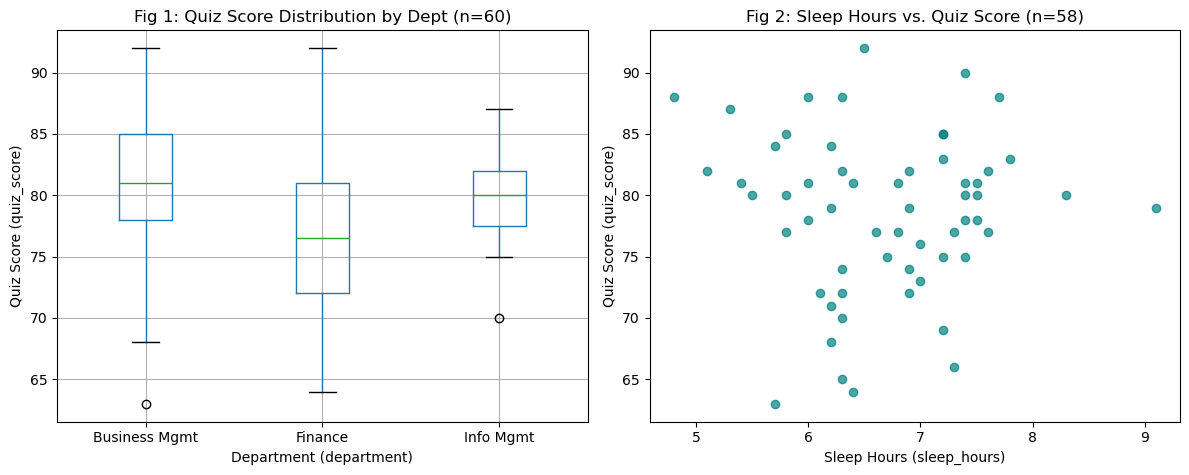

In [4]:
import matplotlib.pyplot as plt

# 重置為預設英文字型設定，確保無字型警告
plt.rcdefaults()

# 建立科系中英對照，僅用於繪圖 X 軸顯示（保留原始 df 不變）
dept_map = {
    "企業管理": "Business Mgmt",
    "資訊管理": "Info Mgmt",
    "金融管理": "Finance"
}
plot_df = df.copy()
plot_df["dept_en"] = plot_df["department"].map(dept_map).fillna(plot_df["department"])

# 繪製 8.3 報告所需的兩張圖表
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 圖 1：各系所測驗成績箱型圖
plot_df.boxplot(column="quiz_score", by="dept_en", ax=axes[0])
axes[0].set_title(f"Fig 1: Quiz Score Distribution by Dept (n={df['quiz_score'].count()})")
axes[0].set_xlabel("Department (department)")
axes[0].set_ylabel("Quiz Score (quiz_score)")
plt.suptitle("")  # 移除 pandas 自動產生的多餘副標題

# 圖 2：睡眠時間與測驗成績散佈圖
valid_sleep = df.dropna(subset=["sleep_hours", "quiz_score"])
axes[1].scatter(valid_sleep["sleep_hours"], valid_sleep["quiz_score"], alpha=0.7, color="teal")
axes[1].set_title(f"Fig 2: Sleep Hours vs. Quiz Score (n={len(valid_sleep)})")
axes[1].set_xlabel("Sleep Hours (sleep_hours)")
axes[1].set_ylabel("Quiz Score (quiz_score)")

plt.tight_layout()
plt.show()

## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：**輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


## 💻 學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：**任務 8「延伸：主張如何連結證據」的示範程式。

**任務：**建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [5]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df[["sleep_hours", "quiz_score"]].dropna().copy()  # TODO：選出睡眠與成績都有資料的列
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473623), '限制': '模擬資料、成績由公式生成，不能推論因果'}


### ✅ 作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [6]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


### ✍️ 作業 08-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：你好，我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。我的任務是建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：挑出"sleep_hours", "quiz_score"這兩欄，然後預設「任一所選欄位是 NaN 的列整列移除」正好等於保留「睡眠與成績都有值」的列，最後讓 pairs 成為獨立物件。總結就是在同一批有效資料上算 Pearson 相關係數，與「有效配對」筆數保持一致。
- 執行或驗證遇到的問題與修正：一開始沒打.copy()，改到原始df，後面才發現並加上.copy()
- 檢查結果及我如何確認：在08-P1的執行驗證中她顯示檢查通過：報告使用的有效配對正確。


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MB｜分析問題與證據報告
**涵蓋：**任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


In [7]:
print("真實欄位名稱：", df.columns.tolist())
display(df.head())

真實欄位名稱： ['student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']


,student_id,department,sleep_hours,screen_time_hours,study_hours,attendance_rate,quiz_score
0,1,資訊管理,9.1,6.0,2.3,95.0,79.0
1,2,金融管理,6.3,4.9,1.5,77.0,74.0
2,3,企業管理,6.1,4.4,0.8,88.0,72.0
3,4,企業管理,5.8,4.9,2.0,84.0,85.0
4,5,企業管理,7.4,2.5,2.4,85.0,90.0


欄位 'sleep_hours' 中數值等於 15 的筆數：0 筆
欄位 'screen_time_hours' 中數值等於 15 的筆數：1 筆
欄位 'study_hours' 中數值等於 15 的筆數：0 筆
--------------------------------------------------
原始總筆數：60 筆 ｜ 有效配對總筆數：60 筆

=== 各科系有效配對人數與平均統計 ===
  department  有效配對人數  平均讀書時數  平均睡眠時數  平均螢幕時數  平均測驗分數
0       企業管理      21    2.66    6.56    4.49   80.67
1       資訊管理      15    2.42    6.75    5.08   79.73
2       金融管理      24    2.34    6.75    5.27   76.58
--------------------------------------------------
=== screen_time_hours 中「15 小時紀錄」兩種處理方式比較 ===
            方法A_人數  方法A_平均時數  方法A_平均分數  方法B_人數  方法B_平均時數  方法B_平均分數
department                                                        
企業管理            21      4.49     80.67      21      4.49     80.67
資訊管理            15      5.08     79.73      14      4.37     79.71
金融管理            24      5.27     76.58      24      5.27     76.58


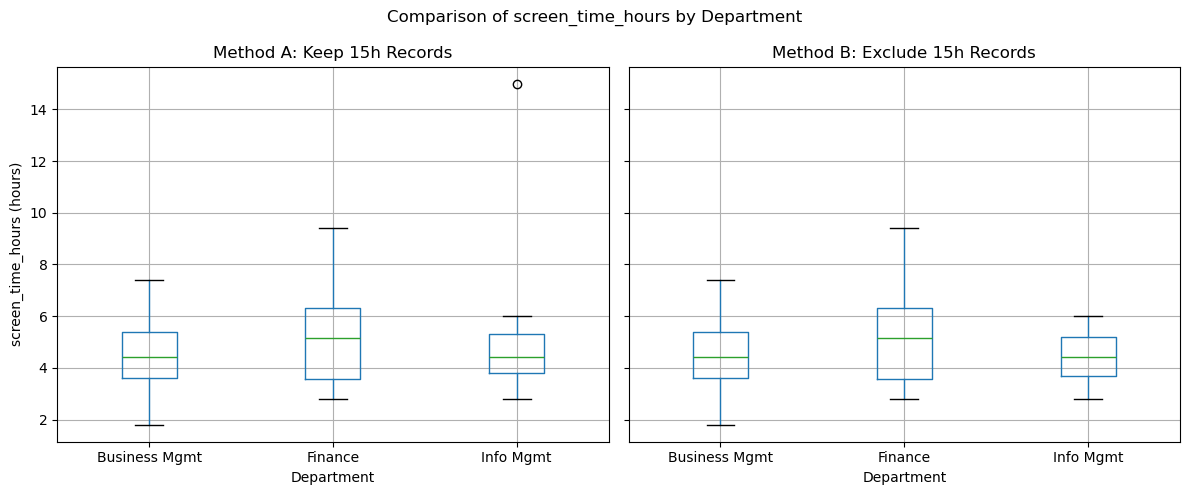

In [8]:
# 學生小任務 MB：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# 查看所有真實欄位名稱，以及前 5 筆資料長什麼樣子

# 學生小任務 MB：請在此撰寫你的程式
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcdefaults()
# ==========================================
# 0. 設定要分析的欄位名稱（已對齊你的 df 真實欄位）
# ==========================================
GROUP_COL = 'department'          # 分組欄位（科系）
TARGET_HOURS_COL = 'screen_time_hours'  # 時數欄位（若題目的 15 小時是指螢幕時數，可改成 'screen_time_hours'）
SCORE_COL = 'quiz_score'          # 配對的另一個關鍵指標（測驗分數）

# 先自動檢查「15 小時」出現在哪個時數欄位中，幫你確認有沒有選錯欄位
for col in ['sleep_hours', 'screen_time_hours', 'study_hours']:
    count_15 = (df[col] == 15).sum()
    print(f"欄位 '{col}' 中數值等於 15 的筆數：{count_15} 筆")
print("-" * 50)

# ==========================================
# 1. 檢查並篩選「有效配對」與計算分組人數、平均
# ==========================================
# 邏輯：必須同時在「目標時數」與「測驗分數」都有非空值 (notna)，才算有效配對
df['is_valid_pair'] = df[TARGET_HOURS_COL].notna() & df[SCORE_COL].notna()
valid_df = df[df['is_valid_pair']].copy()

print(f"原始總筆數：{len(df)} 筆 ｜ 有效配對總筆數：{len(valid_df)} 筆\n")

# 依科系 (department) 計算有效配對人數與各項平均值
summary_stats = valid_df.groupby(GROUP_COL).agg(
    有效配對人數=('is_valid_pair', 'count'),
    平均讀書時數=('study_hours', 'mean'),
    平均睡眠時數=('sleep_hours', 'mean'),
    平均螢幕時數=('screen_time_hours', 'mean'),
    平均測驗分數=('quiz_score', 'mean')
).round(2).reset_index()

print("=== 各科系有效配對人數與平均統計 ===")
print(summary_stats)
print("-" * 50)

# ==========================================
# 2. 針對「15 小時紀錄」進行兩種處理方式的比較
# ==========================================
# 方法 A：保留所有有效配對（包含 15 小時的紀錄）
method_a = valid_df.groupby(GROUP_COL).agg(
    方法A_人數=(TARGET_HOURS_COL, 'count'),
    方法A_平均時數=(TARGET_HOURS_COL, 'mean'),
    方法A_平均分數=(SCORE_COL, 'mean')
)

# 方法 B：排除數值等於 15 小時的紀錄（敏感度分析）
df_no_15 = valid_df[valid_df[TARGET_HOURS_COL] != 15]
method_b = df_no_15.groupby(GROUP_COL).agg(
    方法B_人數=(TARGET_HOURS_COL, 'count'),
    方法B_平均時數=(TARGET_HOURS_COL, 'mean'),
    方法B_平均分數=(SCORE_COL, 'mean')
)

# 合併兩種處理方式的結果，方便在報告中並列比較
comparison_15h = pd.concat([method_a, method_b], axis=1).round(2)
print(f"=== {TARGET_HOURS_COL} 中「15 小時紀錄」兩種處理方式比較 ===")
print(comparison_15h)

# ==========================================
# 3. 繪製分組比較圖表（使用英文標籤避免雲端環境中文字型方框）
# ==========================================
plt.rcParams['axes.unicode_minus'] = False

# 建立科系中英對照字典，僅用於圖表顯示（不更動原始 df）
dept_map = {
    '資訊管理': 'Info Mgmt',
    '金融管理': 'Finance',
    '企業管理': 'Business Mgmt'
}

plot_df_a = valid_df.copy()
plot_df_a['dept_en'] = plot_df_a[GROUP_COL].map(dept_map).fillna(plot_df_a[GROUP_COL])

plot_df_b = df_no_15.copy()
plot_df_b['dept_en'] = plot_df_b[GROUP_COL].map(dept_map).fillna(plot_df_b[GROUP_COL])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# 左圖：方法 A（保留 15 小時紀錄）
plot_df_a.boxplot(column=TARGET_HOURS_COL, by='dept_en', ax=axes[0])
axes[0].set_title('Method A: Keep 15h Records')
axes[0].set_xlabel('Department')
axes[0].set_ylabel(f'{TARGET_HOURS_COL} (hours)')

# 右圖：方法 B（排除 15 小時紀錄）
plot_df_b.boxplot(column=TARGET_HOURS_COL, by='dept_en', ax=axes[1])
axes[1].set_title('Method B: Exclude 15h Records')
axes[1].set_xlabel('Department')

plt.suptitle(f'Comparison of {TARGET_HOURS_COL} by Department')
plt.tight_layout()
plt.show()

### ✍️ 小任務 MB｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：問題：探討不同科系學生的學習／作息時數與測驗成績之分組差異，並比較「保留 15 小時紀錄」與「排除 15 小時紀錄」兩種處理方式對分析結果的影響。

  使用的資料與欄位：使用資料表 df，以 department作為分組依據，搭配 study_hours、sleep_hours、screen_time_hours及 quiz_score篩選有效配對並進行統計分析。
- 實際輸出與至少一項依據數字的觀察：實際輸出摘要：原始資料共60筆，篩選後有效配對共60筆；其中數值等於 15 小時的紀錄出現在screen_time_hours欄位，共1筆。

  依據數字的觀察：科系整體表現：企業管理系的平均讀書時數最高（2.66 小時）、平均螢幕時數最低（4.49 小時），其平均測驗分數也最高（80.67 分）；金融管理系平均螢幕時數最高（5.27 小時），平均測驗分數相對最低（76.58 分）。
- 圖表或模型結果的解讀（依任務要求）：透過左右並列箱型圖比較screen_time_hours的分布：在左圖Method A 中，Info Mgmt上方在 Y 軸 15 的位置出現一個明顯的離群值圓點，使該組整體全距大幅拉長；而在右圖Method B 排除該筆紀錄後，該離群點消失，資訊管理系的整體分布範圍收斂至約2.8至6.0小時之間，顯示單一極端值會顯著拉高小組平均值（由 4.37 拉高至 5.08），但對中位數與四分位距（IQR）影響較小
- 資料品質、模擬資料或評估限制：本資料集中資訊管理系樣本數較少（15 人），單一 15 小時的極端螢幕使用紀錄便足以讓該系平均時數產生 0.71 小時的偏移，顯示小樣本下的平均值對極端值相當敏感
- 驗證方法與結果：方法：有效配對人數加總與原始比數一致。

  結果：所有加總筆數、差額與箱型圖視覺呈現之離群點數量皆完全吻合，無NaN或程式錯誤。
- AI 工具、實際提示詞、人工修改與遇到的問題：gemini，

  提示詞：你好我是 Python 初學者，請協助我完成以下資料分析小任務：請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。

  問題：最初使用假設欄位名稱、瀏覽器執行環境無內建微軟正黑體，繪圖時出現 findfont 警告、初始將目標欄位設為 study_hours 時發現無 15 小時紀錄，導致兩個圖相同
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
- 重新執行是否成功及環境或檔案需求：成功，需先執行上方載入並建立 df 的資料準備儲存格；執行環境需具備 pandas、numpy 與 matplotlib 套件
